In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import eclipsr as ecl

import time
from pathlib import Path
from astropy.io import fits

import lightkurve as lk

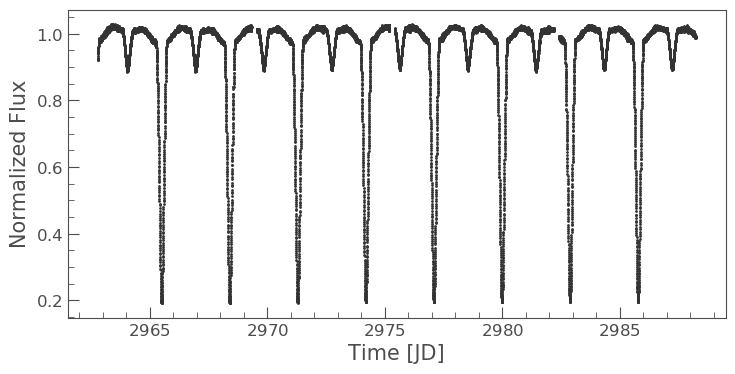

In [2]:
path = sorted(Path('../lightcurves/tic_231973885').rglob('*.fits'))[0]

with fits.open(path) as hdul:
    d = hdul[1].data
    t = np.asarray(d['TIME'], dtype=float)
    f = np.asarray(d['SAP_FLUX'], dtype=float)
    #q = np.asarray(d['QUALITY']) == 0

good = np.isfinite(t) & np.isfinite(f)
t, f = t[good], f[good]

lc = lk.LightCurve(time=t, flux=f).remove_nans().normalize()
lc.scatter();

In [3]:
times, flux = ecl.utility.ingest_signal(t, f, tess_sectors=False)


result = ecl.find_eclipses(times, flux, mode=2, tess_sectors=False)
t_0, period, score, sine_like, wide, n_kernel, width_stats, depth_stats, ecl_mid, widths, depths, ratios, added_snr, ecl_indices, flags_lrf, flags_pst = result

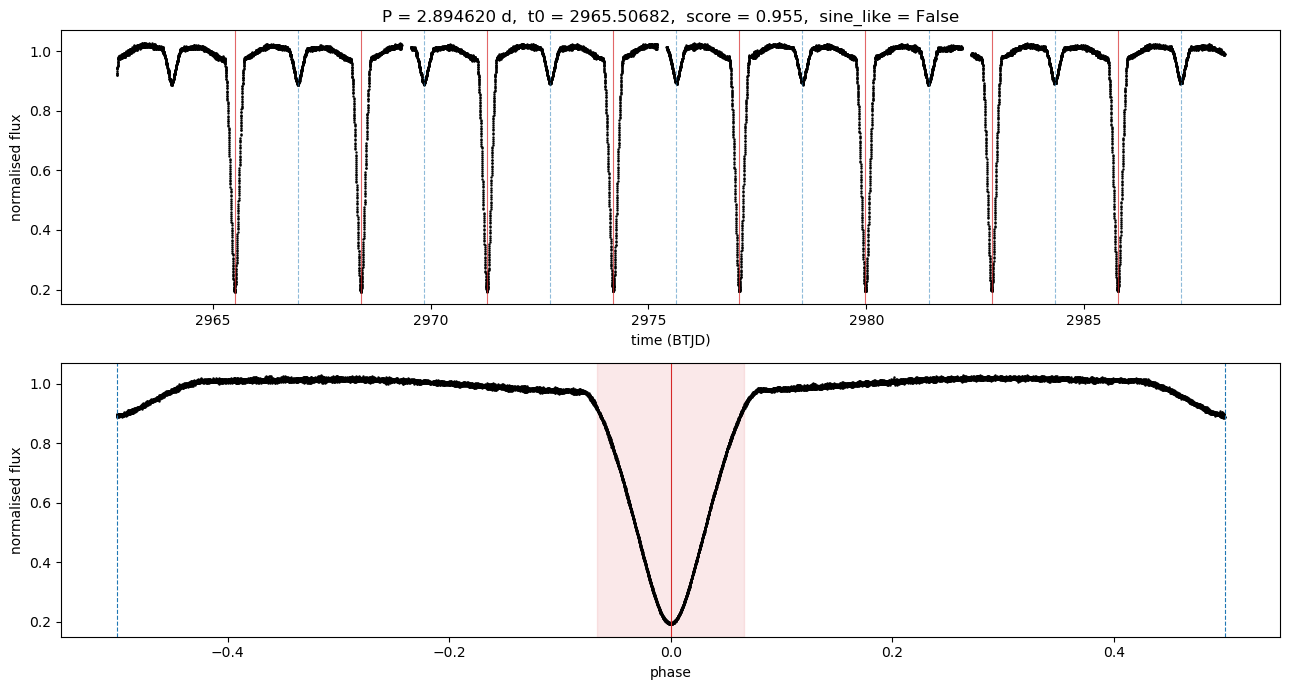

In [4]:
dur_pri   = width_stats[0, 0]
depth_pri = depth_stats[0, 0]

fig, ax = plt.subplots(2, 1, figsize=(13, 7))

# --- 1. zaman serisi ---
ax[0].plot(times, flux, '.', ms=1.5, color='k')
n0 = int(np.floor((times.min() - t_0) / period))
n1 = int(np.ceil((times.max() - t_0) / period))
for n in range(n0, n1 + 1):
    tp = t_0 + n * period
    if times.min() <= tp <= times.max():
        ax[0].axvline(tp, color='tab:red', lw=0.8, alpha=0.7)
        ax[0].axvline(tp + period / 2, color='tab:blue', lw=0.8,
                      alpha=0.5, ls='--')
ax[0].set_xlabel('time (BTJD)')
ax[0].set_ylabel('normalised flux')
ax[0].set_title(f'P = {period:.6f} d,  t0 = {t_0:.5f},  '
                f'score = {score:.3f},  sine_like = {sine_like}')

# --- 2. katlanmış eğri, birincil derinlik ve süre ---
phase = ((times - t_0) / period + 0.5) % 1 - 0.5
o = np.argsort(phase)
ax[1].plot(phase[o], flux[o], '.', ms=1.5, color='k')
ax[1].axvline(0, color='tab:red', lw=0.8)
ax[1].axvline(0.5, color='tab:blue', lw=0.8, ls='--')
ax[1].axvline(-0.5, color='tab:blue', lw=0.8, ls='--')

base = np.median(flux)
dur_ph = dur_pri / period
ax[1].axvspan(-dur_ph / 2, dur_ph / 2, color='tab:red', alpha=0.10)
#ax[1].annotate('', xy=(0, base * (1 - depth_pri)), xytext=(0, base),
               #arrowprops=dict(arrowstyle='<->', color='tab:red', lw=1.2))
#ax[1].text(dur_ph / 2 + 0.02, base * (1 - depth_pri / 2),
           #f'depth {depth_pri:.3f}\n{dur_pri * 24:.2f} h',
           #color='tab:red', va='center', fontsize=14)

ax[1].set_xlabel('phase')
ax[1].set_ylabel('normalised flux')

plt.tight_layout(); plt.show()

In [5]:
print(f"t0: {t_0:.5f}")
print(f"p: {period:.3f}")
print(f"eclipse_score: {score:.4f}")
print(f"sine like? : {sine_like}")
print(f"wide: {wide}")
print(f"n_kernel: {n_kernel}")
print(f"width_stats : {width_stats}")
print(f"depth_stats: {depth_stats}")
print(f"ecl_mid: {ecl_mid}")
print(f"widths: {widths}")
print(f"depths: {depths}")
#print(f"ratios: {ratios}")
print(f"added_snr: {added_snr}")
#print(f"ecl_indices: {ecl_indices}")
print(f"flags_lrf: {flags_lrf}")
print(f"flags_pst: {flags_pst}")

t0: 2965.50682
p: 2.895
eclipse_score: 0.9550
sine like? : False
wide: False
n_kernel: 70
width_stats : [[0.38315347 0.00189309]
 [0.38147536 0.00851037]]
depth_stats: [[0.66331409 0.00268026]
 [0.09749656 0.00155598]]
ecl_mid: [2964.06134548 2965.50682098 2966.95020977 2968.40123451 2969.85572889
 2971.29598497 2972.74422475 2974.19211536 2975.64209059 2977.08478034
 2978.53545404 2979.98126359 2981.42741771 2982.87565272 2984.31937168
 2985.77003274 2987.21721991]
widths: [0.37221996 0.38194116 0.38888472 0.38193965 0.37777239 0.38054952
 0.38610439 0.38193742 0.37916126 0.3833283  0.37777195 0.38610439
 0.37082624 0.38610311 0.38054708 0.38332424 0.39999025]
depths: [0.09690414 0.66082347 0.09877534 0.66091797 0.09673759 0.66013768
 0.09794898 0.66227597 0.09673925 0.66540559 0.0967451  0.66775543
 0.09505846 0.6664638  0.09761002 0.66273282 0.10095014]
added_snr: [ 2144.20851683 14280.91337744  2107.30578062 14281.45354236
  2107.0219926  14306.07848631  2164.57078337 14315.1476414

In [ ]:
lrf, pst = np.asarray(flags_lrf), np.asarray(flags_pst)
full_pri = (lrf == 0) & (pst == 1)

dur_obs, dep_obs = [], []
for k in np.flatnonzero(full_pri):
    i1, i2, i3, i4 = ecl_indices[k]
    bottom = np.median(flux[i2:i3+1]) if i3 > i2 else flux[i2]
    base   = np.median(np.r_[flux[i1-5:i1], flux[i4+1:i4+6]])
    dur_obs.append(times[i4] - times[i1])
    dep_obs.append(1 - bottom / base)

dur_obs, dep_obs = np.array(dur_obs), np.array(dep_obs)
print(f'ECLIPSR : depth {depth_stats[0,0]:.4f} ; duration {width_stats[0,0]*24:.2f} sa')
print(f'from flux  : depth {dep_obs.mean():.4f} ± {dep_obs.std():.4f}'
      f', duration {dur_obs.mean()*24:.2f} ± {dur_obs.std()*24:.2f} sa')
print(f'ratio    : {depth_stats[0,0]/dep_obs.mean():.3f}')

ECLIPSR : depth 0.6633  süre 9.20 sa
akıdan  : depth 0.7902 ± 0.0010süre 9.20 ± 0.05 sa
oran    : 0.839
